# 04b — Studi Ablasi: Model C (Time-Series + Fitur Transformer)

**Tugas 3, Butir 3**: Studi ablasi untuk menganalisis kontribusi fitur secara sistematis.

Notebook ini melatih dan membandingkan **tiga varian model** sesuai spesifikasi tugas:

| Model | Fitur | Deskripsi |
|---|---|---|
| **Model A** | Hanya time-series (lag return + volatilitas) | Baseline time-series murni |
| **Model B** | Time-series + NLP dasar (VADER, LM, TF-IDF SVD) | Baseline NLP (Tugas 2) |
| **Model C** | Time-series + Transformer embeddings (FinBERT PCA) | Model Tugas 3 |
| **Model C+** | Time-series + NLP dasar + Transformer embeddings | Gabungan semua fitur |

Semua model menggunakan **XGBoost** dengan hyperparameter yang **identik** agar perbandingan adil — perbedaan performa hanya berasal dari fitur.

### Target

- **Klasifikasi 3-class**: `target` (NAIK / STABIL / TURUN) — metrik primer: **Macro-F1**
- **Regresi**: `kurs_besok` (nilai kurs JISDOR hari berikutnya) — metrik primer: **RMSE**

### Input

- `data/feature_extracted/model_dataset_transformer.csv` (output notebook 03b)
- `data/feature_extracted/model_dataset.csv` (output notebook 03, untuk fitur TF-IDF SVD)

### Catatan leakage

Split memakai kolom `split` dari dataset. Val dipakai untuk early stopping, test hanya dievaluasi sekali di akhir. Tidak ada fit ulang TF-IDF/SVD/PCA di sini.

## 1. Import dan setup

In [1]:
import warnings
warnings.filterwarnings("ignore")

import json
import sys
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

import xgboost as xgb
from sklearn.utils.class_weight import compute_sample_weight


def find_repo_root():
    here = Path.cwd().resolve()
    for d in (here, *here.parents):
        if (d / "data").is_dir() and (d / "src").is_dir():
            return d
    raise FileNotFoundError(
        f"Root repository tidak ditemukan dari {here}. "
        "Jalankan notebook dari dalam repository nlp-trio-bertiga."
    )

ROOT = find_repo_root()
sys.path.insert(0, str(ROOT))

from src.jisdor.target_formulation import THRESHOLD_PCT, label_direction
from src.models.metrics import (
    LABEL_ORDER, evaluate_classifier, evaluate_regression,
    directional_hit_from_regression, print_classifier, print_regressor,
)
from src.models.naive_baseline import predict_persistence, predict_majority

FEATURE_DIR = ROOT / "data" / "feature_extracted"
RESULTS_DIR = ROOT / "results"
RESULTS_DIR.mkdir(parents=True, exist_ok=True)

print("Project root :", ROOT)
print("Label kelas  :", LABEL_ORDER)
print("Threshold    : ±%.2f%% pada pct_change harian" % THRESHOLD_PCT)

Project root : C:\kuliahlocal\smt 5\NLP\nlp-trio-bertiga
Label kelas  : ['NAIK', 'STABIL', 'TURUN']
Threshold    : ±0.10% pada pct_change harian


## 2. Muat dataset

Memuat dua dataset:
1. `model_dataset_transformer.csv` — berisi fitur kurs, lexicon, **dan** transformer PCA (output 03b)
2. `model_dataset.csv` — berisi fitur kurs, lexicon, **dan** TF-IDF SVD (output 03)

Kolom TF-IDF SVD diambil dari dataset kedua karena dataset transformer tidak menyimpannya.

In [2]:
# Dataset utama (dengan transformer embeddings)
df = pd.read_csv(FEATURE_DIR / "model_dataset_transformer.csv")
df["date"] = pd.to_datetime(df["date"], errors="coerce")
df = df.sort_values("date").reset_index(drop=True)

# Hitung target jika belum ada
if "target" not in df.columns:
    print("PERINGATAN: kolom `target` tidak ada. Dihitung ulang dari kurs_besok.")
    pct_besok = (df["kurs_besok"] / df["kurs_jisdor"] - 1) * 100
    df["target"] = pct_besok.apply(lambda x: label_direction(x, THRESHOLD_PCT))

# Hitung delta_besok jika belum ada
if "delta_besok" not in df.columns:
    df["delta_besok"] = df["kurs_besok"] - df["kurs_jisdor"]

# Ambil kolom TF-IDF SVD dari model_dataset.csv (untuk Model B)
df_old = pd.read_csv(FEATURE_DIR / "model_dataset.csv")
df_old["date"] = pd.to_datetime(df_old["date"], errors="coerce")
tfidf_svd_cols = sorted([c for c in df_old.columns if c.startswith("tfidf_svd_")],
                        key=lambda x: int(x.split("_")[-1]))

# Merge TF-IDF SVD ke dataset utama via date
if tfidf_svd_cols and tfidf_svd_cols[0] not in df.columns:
    df = df.merge(df_old[["date"] + tfidf_svd_cols], on="date", how="left")
    print(f"TF-IDF SVD columns merged: {len(tfidf_svd_cols)} kolom")

print(f"Total baris : {len(df):,} | kolom: {df.shape[1]}")
print(f"Periode     : {df['date'].min().date()} -> {df['date'].max().date()}")
print(f"Split       :\n{df['split'].value_counts().reindex(['train', 'val', 'test']).to_string()}")

TF-IDF SVD columns merged: 50 kolom
Total baris : 1,193 | kolom: 893
Periode     : 2021-09-08 -> 2026-08-28
Split       :
split
train    836
val      178
test     179


## 3. Definisi kelompok fitur

Setiap varian model menggunakan subset fitur yang berbeda. Definisi di sini menjadi satu-satunya sumber kebenaran.

In [3]:
# --- Kelompok fitur ---

# Fitur time-series (kurs historis)
FEAT_TS = ["ret_lag1", "ret_lag2", "ret_lag3", "ret_std5"]

# Fitur NLP dasar (lexicon: VADER + Loughran-McDonald)
FEAT_LEXICON = [
    "vader_title_mean", "vader_body_mean", "vader_body_min", "vader_neg_share",
    "lm_negative_mean", "lm_positive_mean", "lm_uncertainty_mean",
    "lm_litigious_mean", "lm_constraining_mean", "lm_net_mean", "no_news",
]

# Fitur TF-IDF SVD (dari notebook 03)
FEAT_TFIDF = tfidf_svd_cols

# Fitur Transformer PCA (dari notebook 03b)
FEAT_TRANSFORMER = sorted([c for c in df.columns if c.startswith("transformer_")],
                          key=lambda x: int(x.split("_")[-1]))

# --- Definisi varian model (studi ablasi) ---
MODEL_VARIANTS = {
    "Model A: Hanya Time-Series":          FEAT_TS,
    "Model B: TS + NLP Dasar":             FEAT_TS + FEAT_LEXICON + FEAT_TFIDF,
    "Model C: TS + Transformer":           FEAT_TS + FEAT_TRANSFORMER,
    "Model C+: TS + NLP Dasar + Transformer": FEAT_TS + FEAT_LEXICON + FEAT_TFIDF + FEAT_TRANSFORMER,
}

print("Kelompok fitur:")
print(f"  Time-series     : {len(FEAT_TS)} fitur")
print(f"  Lexicon (NLP)   : {len(FEAT_LEXICON)} fitur")
print(f"  TF-IDF SVD      : {len(FEAT_TFIDF)} fitur")
print(f"  Transformer PCA : {len(FEAT_TRANSFORMER)} fitur")
print()
print("Varian model:")
for name, feats in MODEL_VARIANTS.items():
    print(f"  {name:45s} → {len(feats)} fitur")

Kelompok fitur:
  Time-series     : 4 fitur
  Lexicon (NLP)   : 11 fitur
  TF-IDF SVD      : 50 fitur
  Transformer PCA : 50 fitur

Varian model:
  Model A: Hanya Time-Series                    → 4 fitur
  Model B: TS + NLP Dasar                       → 65 fitur
  Model C: TS + Transformer                     → 54 fitur
  Model C+: TS + NLP Dasar + Transformer        → 115 fitur


## 4. Persiapan data

In [4]:
# Encoding label 3-class: NAIK=0, STABIL=1, TURUN=2
LABEL2ID = {lab: i for i, lab in enumerate(LABEL_ORDER)}
ID2LABEL = {i: lab for lab, i in LABEL2ID.items()}

# Buat splits
splits = {s: df[df["split"] == s].sort_values("date").copy() for s in ["train", "val", "test"]}
tr, va, te = splits["train"], splits["val"], splits["test"]

# Target klasifikasi dan regresi
y_clf   = {s: d["target"].map(LABEL2ID).astype(int) for s, d in splits.items()}
y_reg   = {s: d["kurs_besok"].astype(float) for s, d in splits.items()}
y_delta = {s: d["delta_besok"].astype(float) for s, d in splits.items()}
kurs_today = {s: d["kurs_jisdor"].astype(float).to_numpy() for s, d in splits.items()}

# Sample weight (balanced) untuk klasifikasi
w_train = compute_sample_weight(class_weight="balanced", y=y_clf["train"])

# Verifikasi: cek NaN pada semua fitur yang akan dipakai
all_feats = set()
for feats in MODEL_VARIANTS.values():
    all_feats.update(feats)
nan_count = df[list(all_feats)].isna().sum().sum()
print(f"NaN pada semua fitur: {nan_count}")
if nan_count > 0:
    print("PERINGATAN: ada NaN pada fitur. Mengisi dengan 0.")
    df[list(all_feats)] = df[list(all_feats)].fillna(0)
    splits = {s: df[df["split"] == s].sort_values("date").copy() for s in ["train", "val", "test"]}
    tr, va, te = splits["train"], splits["val"], splits["test"]

print(f"\nDistribusi target (train): {tr['target'].value_counts().to_dict()}")
print(f"Distribusi target (test) : {te['target'].value_counts().to_dict()}")
print({s: len(d) for s, d in splits.items()})

NaN pada semua fitur: 0

Distribusi target (train): {'NAIK': 330, 'STABIL': 254, 'TURUN': 252}
Distribusi target (test) : {'NAIK': 77, 'TURUN': 52, 'STABIL': 50}
{'train': 836, 'val': 178, 'test': 179}


## 5. Referensi naive baseline

Dihitung ulang pada baris yang sama dengan model, agar perbandingannya adil.

In [5]:
all_results = []

def add_result(model, split, task, metrics):
    all_results.append({"model": model, "split": split, "task": task, **{
        k: v for k, v in metrics.items() if k not in ("classification_report", "confusion_matrix")}})

rmse_naive = {}
for s in ["val", "test"]:
    d = splits[s]
    y_true_lab = d["target"].to_numpy()

    # klasifikasi
    r_p = evaluate_classifier(y_true_lab, predict_persistence(d["target"]), include_kappa=True)
    r_m = evaluate_classifier(y_true_lab, predict_majority(tr["target"], len(d)), include_kappa=True)
    add_result("Naive Persistence", s, "clf", r_p)
    add_result("Naive Majority-Class", s, "clf", r_m)

    # regresi
    r_r = evaluate_regression(y_reg[s], kurs_today[s], include_mape=True)
    rmse_naive[s] = r_r["rmse"]
    r_r["skill_vs_naive"] = 0.0
    add_result("Naive Random Walk", s, "reg", r_r)

    print(f"[{s}] Persistence Macro-F1={r_p['macro_f1']:.4f} | "
          f"Majority Macro-F1={r_m['macro_f1']:.4f} | Persistence RMSE={r_r['rmse']:.4f}")

[val] Persistence Macro-F1=0.3692 | Majority Macro-F1=0.1862 | Persistence RMSE=55.8789
[test] Persistence Macro-F1=0.3562 | Majority Macro-F1=0.2005 | Persistence RMSE=51.1231


## 6. Factory XGBoost

Hyperparameter **identik** untuk semua varian model, agar perbandingan hanya mengukur kontribusi fitur.

In [6]:
def make_xgb_classifier():
    return xgb.XGBClassifier(
        objective="multi:softprob",
        num_class=len(LABEL_ORDER),
        eval_metric="mlogloss",
        n_estimators=500,
        max_depth=3,
        learning_rate=0.03,
        subsample=0.8,
        colsample_bytree=0.8,
        min_child_weight=5,
        reg_alpha=0.1,
        reg_lambda=1.0,
        random_state=42,
        n_jobs=-1,
        early_stopping_rounds=30,
    )

def make_xgb_regressor():
    return xgb.XGBRegressor(
        objective="reg:squarederror",
        eval_metric="rmse",
        n_estimators=500,
        max_depth=3,
        learning_rate=0.03,
        subsample=0.8,
        colsample_bytree=0.8,
        min_child_weight=5,
        reg_alpha=0.1,
        reg_lambda=1.0,
        random_state=42,
        n_jobs=-1,
        early_stopping_rounds=30,
    )

print("Factory XGBoost siap.")

Factory XGBoost siap.


## 7. Jalankan studi ablasi

Loop melalui semua varian model. Setiap varian dilatih untuk **klasifikasi** dan **regresi**, dievaluasi pada val dan test.

In [7]:
# Simpan model dan metrik per varian
clf_models = {}
reg_models = {}
clf_metrics_all = {}
reg_metrics_all = {}
clf_preds = {}
reg_preds = {}

for variant_name, feat_cols in MODEL_VARIANTS.items():
    print(f"\n{'='*70}")
    print(f"  {variant_name} ({len(feat_cols)} fitur)")
    print(f"{'='*70}")
    
    # Fitur per split
    X = {s: splits[s][feat_cols] for s in ["train", "val", "test"]}
    
    # ---- KLASIFIKASI ----
    clf = make_xgb_classifier()
    clf.fit(
        X["train"], y_clf["train"],
        sample_weight=w_train,
        eval_set=[(X["val"], y_clf["val"])],
        verbose=False,
    )
    clf_models[variant_name] = clf
    print(f"  CLF best iteration: {clf.best_iteration}")
    
    pred_clf = {s: pd.Series(clf.predict(X[s])).map(ID2LABEL).to_numpy()
                for s in ["val", "test"]}
    clf_preds[variant_name] = pred_clf
    
    for s in ["val", "test"]:
        m = evaluate_classifier(splits[s]["target"].to_numpy(), pred_clf[s], include_kappa=True)
        clf_metrics_all[(variant_name, s)] = m
        add_result(variant_name, s, "clf", m)
        print(f"  [{s}] Accuracy={m['accuracy']:.4f}  Macro-F1={m['macro_f1']:.4f}  Kappa={m.get('kappa', 'N/A')}")
    
    # ---- REGRESI ----
    reg = make_xgb_regressor()
    reg.fit(
        X["train"], y_delta["train"],
        eval_set=[(X["val"], y_delta["val"])],
        verbose=False,
    )
    reg_models[variant_name] = reg
    print(f"  REG best iteration: {reg.best_iteration}")
    
    pred_reg = {s: kurs_today[s] + reg.predict(X[s]) for s in ["val", "test"]}
    reg_preds[variant_name] = pred_reg
    
    for s in ["val", "test"]:
        m = evaluate_regression(y_reg[s], pred_reg[s], rmse_naive=rmse_naive[s], include_mape=True)
        m["directional_hit"] = directional_hit_from_regression(kurs_today[s], y_reg[s], pred_reg[s])
        reg_metrics_all[(variant_name, s)] = m
        add_result(variant_name, s, "reg", m)
        print(f"  [{s}] RMSE={m['rmse']:.2f}  MAE={m['mae']:.2f}  Skill={m.get('skill_vs_naive', 'N/A')}")

print(f"\n{'='*70}")
print("  Semua varian selesai dilatih dan dievaluasi.")
print(f"{'='*70}")


  Model A: Hanya Time-Series (4 fitur)
  CLF best iteration: 34
  [val] Accuracy=0.3258  Macro-F1=0.3210  Kappa=-0.02
  [test] Accuracy=0.3687  Macro-F1=0.3636  Kappa=0.0452
  REG best iteration: 21
  [val] RMSE=55.65  MAE=40.57  Skill=0.0041
  [test] RMSE=51.10  MAE=38.20  Skill=0.0004

  Model B: TS + NLP Dasar (65 fitur)
  CLF best iteration: 0
  [val] Accuracy=0.3315  Macro-F1=0.3287  Kappa=-0.0056
  [test] Accuracy=0.2626  Macro-F1=0.2612  Kappa=-0.1127
  REG best iteration: 0
  [val] RMSE=55.86  MAE=40.66  Skill=0.0003
  [test] RMSE=50.91  MAE=38.16  Skill=0.0042

  Model C: TS + Transformer (54 fitur)
  CLF best iteration: 37
  [val] Accuracy=0.3034  Macro-F1=0.2953  Kappa=-0.0336
  [test] Accuracy=0.3408  Macro-F1=0.3322  Kappa=0.0223
  REG best iteration: 2
  [val] RMSE=55.84  MAE=40.76  Skill=0.0006
  [test] RMSE=50.97  MAE=38.16  Skill=0.003

  Model C+: TS + NLP Dasar + Transformer (115 fitur)
  CLF best iteration: 24
  [val] Accuracy=0.3539  Macro-F1=0.3482  Kappa=0.0462


## 8. Matriks ablasi: tabel ringkasan

Tabel perbandingan performa di seluruh varian — inilah **matriks ablasi** yang diminta Tugas 3.

In [8]:
res = pd.DataFrame(all_results)

clf_cols = ["model", "split", "accuracy", "balanced_accuracy", "macro_f1", "kappa"]
reg_cols = ["model", "split", "rmse", "mae", "mape", "skill_vs_naive", "directional_hit"]

clf_table = res[res["task"] == "clf"][clf_cols].round(4)
reg_table = res[res["task"] == "reg"][reg_cols].round(4)

print("=" * 90)
print("  MATRIKS ABLASI — KLASIFIKASI 3-class (primer: Macro-F1)")
print("=" * 90)
display(clf_table.sort_values(["split", "macro_f1"], ascending=[True, False]))

print()
print("=" * 90)
print("  MATRIKS ABLASI — REGRESI kurs_besok (primer: RMSE)")
print("=" * 90)
display(reg_table.sort_values(["split", "rmse"]))

  MATRIKS ABLASI — KLASIFIKASI 3-class (primer: Macro-F1)


,model,split,accuracy,balanced_accuracy,macro_f1,kappa
7,Model A: Hanya Time-Series,test,0.3687,0.3668,0.3636,0.0452
3,Naive Persistence,test,0.3687,0.3562,0.3562,0.0326
19,Model C+: TS + NLP Dasar + Transformer,test,0.3408,0.3493,0.3404,0.0279
15,Model C: TS + Transformer,test,0.3408,0.3504,0.3322,0.0223
11,Model B: TS + NLP Dasar,test,0.2626,0.2630,0.2612,-0.1127
4,Naive Majority-Class,test,0.4302,0.3333,0.2005,0.0000
0,Naive Persistence,val,0.3764,0.3695,0.3692,0.0577
18,Model C+: TS + NLP Dasar + Transformer,val,0.3539,0.3690,0.3482,0.0462
10,Model B: TS + NLP Dasar,val,0.3315,0.3321,0.3287,-0.0056
6,Model A: Hanya Time-Series,val,0.3258,0.3230,0.3210,-0.0200



  MATRIKS ABLASI — REGRESI kurs_besok (primer: RMSE)


,model,split,rmse,mae,mape,skill_vs_naive,directional_hit
13,Model B: TS + NLP Dasar,test,50.9095,38.1646,0.2192,0.0042,0.5810
21,Model C+: TS + NLP Dasar + Transformer,test,50.9178,38.1982,0.2194,0.0040,0.5810
17,Model C: TS + Transformer,test,50.9709,38.1556,0.2191,0.0030,0.5810
9,Model A: Hanya Time-Series,test,51.1018,38.2011,0.2194,0.0004,0.5531
5,Naive Random Walk,test,51.1231,38.5419,0.2214,0.0000,NaN
8,Model A: Hanya Time-Series,val,55.6490,40.5738,0.2461,0.0041,0.5337
16,Model C: TS + Transformer,val,55.8433,40.7649,0.2473,0.0006,0.5169
12,Model B: TS + NLP Dasar,val,55.8620,40.6641,0.2467,0.0003,0.5281
2,Naive Random Walk,val,55.8789,40.7697,0.2473,0.0000,NaN
20,Model C+: TS + NLP Dasar + Transformer,val,55.8924,40.6833,0.2468,-0.0002,0.5281


## 9. Visualisasi perbandingan: Klasifikasi

Bar chart Macro-F1 untuk setiap varian pada val dan test.

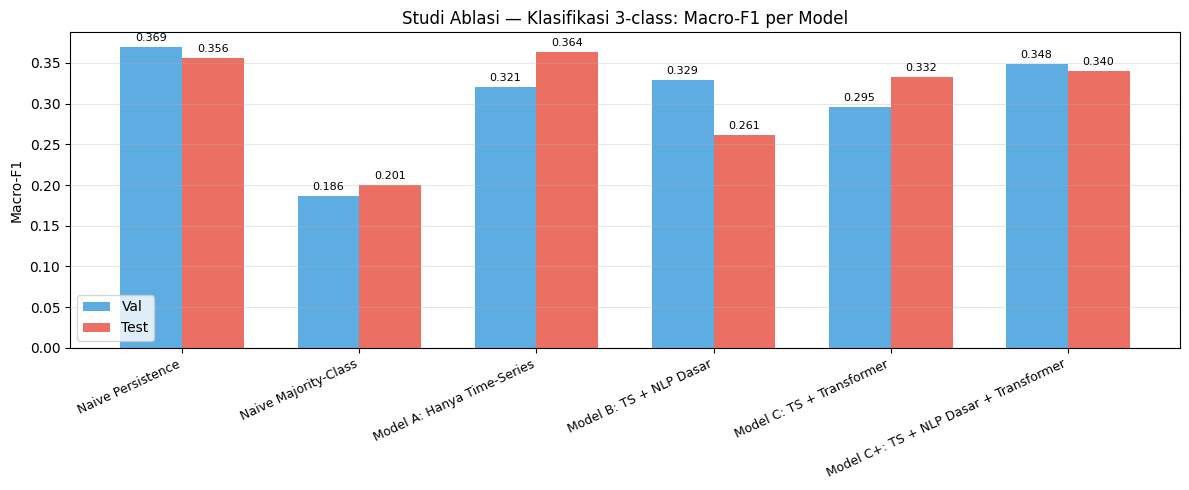

In [9]:
# Ambil Macro-F1 per model per split (hanya klasifikasi, bukan naive)
clf_test = clf_table[clf_table["split"] == "test"].copy()
clf_val  = clf_table[clf_table["split"] == "val"].copy()

model_names = clf_test["model"].tolist()
f1_test = clf_test.set_index("model")["macro_f1"].reindex(model_names).values
f1_val  = clf_val.set_index("model")["macro_f1"].reindex(model_names).values

x = np.arange(len(model_names))
width = 0.35

fig, ax = plt.subplots(figsize=(12, 5))
bars_val  = ax.bar(x - width/2, f1_val,  width, label="Val",  color="#3498db", alpha=0.8)
bars_test = ax.bar(x + width/2, f1_test, width, label="Test", color="#e74c3c", alpha=0.8)

ax.set_ylabel("Macro-F1")
ax.set_title("Studi Ablasi — Klasifikasi 3-class: Macro-F1 per Model")
ax.set_xticks(x)
ax.set_xticklabels(model_names, rotation=25, ha="right", fontsize=9)
ax.legend()
ax.grid(axis="y", alpha=0.3)

# Tambah angka di atas bar
for bar in bars_val:
    ax.text(bar.get_x() + bar.get_width()/2, bar.get_height() + 0.005,
            f"{bar.get_height():.3f}", ha="center", va="bottom", fontsize=8)
for bar in bars_test:
    ax.text(bar.get_x() + bar.get_width()/2, bar.get_height() + 0.005,
            f"{bar.get_height():.3f}", ha="center", va="bottom", fontsize=8)

plt.tight_layout()
plt.savefig(RESULTS_DIR / "04b_ablasi_classification.png", dpi=150)
plt.show()

## 10. Visualisasi perbandingan: Regresi

Bar chart RMSE untuk setiap varian pada val dan test.

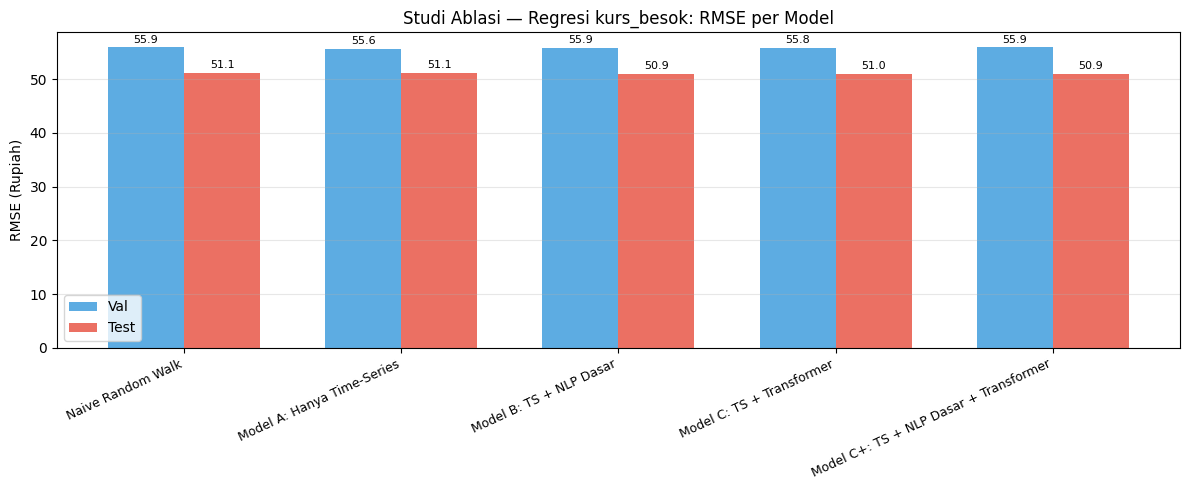

In [10]:
reg_test = reg_table[reg_table["split"] == "test"].copy()
reg_val  = reg_table[reg_table["split"] == "val"].copy()

model_names_reg = reg_test["model"].tolist()
rmse_test = reg_test.set_index("model")["rmse"].reindex(model_names_reg).values
rmse_val  = reg_val.set_index("model")["rmse"].reindex(model_names_reg).values

x = np.arange(len(model_names_reg))

fig, ax = plt.subplots(figsize=(12, 5))
bars_val  = ax.bar(x - width/2, rmse_val,  width, label="Val",  color="#3498db", alpha=0.8)
bars_test = ax.bar(x + width/2, rmse_test, width, label="Test", color="#e74c3c", alpha=0.8)

ax.set_ylabel("RMSE (Rupiah)")
ax.set_title("Studi Ablasi — Regresi kurs_besok: RMSE per Model")
ax.set_xticks(x)
ax.set_xticklabels(model_names_reg, rotation=25, ha="right", fontsize=9)
ax.legend()
ax.grid(axis="y", alpha=0.3)

for bar in bars_val:
    ax.text(bar.get_x() + bar.get_width()/2, bar.get_height() + 0.5,
            f"{bar.get_height():.1f}", ha="center", va="bottom", fontsize=8)
for bar in bars_test:
    ax.text(bar.get_x() + bar.get_width()/2, bar.get_height() + 0.5,
            f"{bar.get_height():.1f}", ha="center", va="bottom", fontsize=8)

plt.tight_layout()
plt.savefig(RESULTS_DIR / "04b_ablasi_regression.png", dpi=150)
plt.show()

## 11. Confusion matrices per varian (test set)

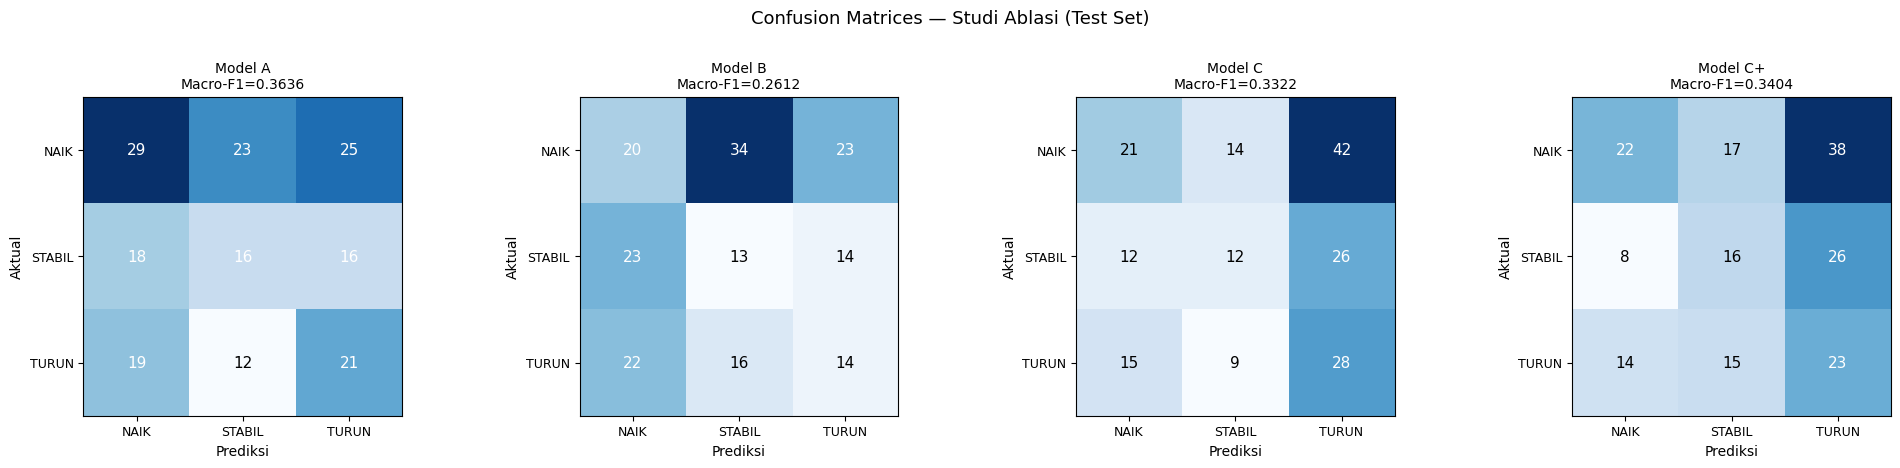

In [11]:
variant_names = list(MODEL_VARIANTS.keys())
n_variants = len(variant_names)

fig, axes = plt.subplots(1, n_variants, figsize=(5 * n_variants, 4.5))
if n_variants == 1:
    axes = [axes]

for ax, vname in zip(axes, variant_names):
    cm = np.array(clf_metrics_all[(vname, "test")]["confusion_matrix"])
    im = ax.imshow(cm, cmap="Blues")
    ax.set_xticks(range(3)); ax.set_xticklabels(LABEL_ORDER, fontsize=9)
    ax.set_yticks(range(3)); ax.set_yticklabels(LABEL_ORDER, fontsize=9)
    ax.set_xlabel("Prediksi")
    ax.set_ylabel("Aktual")
    # Judul singkat
    short = vname.split(":")[0]
    f1 = clf_metrics_all[(vname, "test")]["macro_f1"]
    ax.set_title(f"{short}\nMacro-F1={f1:.4f}", fontsize=10)
    for i in range(3):
        for j in range(3):
            ax.text(j, i, cm[i, j], ha="center", va="center",
                    color="white" if cm[i, j] > cm.max() / 2 else "black", fontsize=11)

plt.suptitle("Confusion Matrices — Studi Ablasi (Test Set)", fontsize=13, y=1.02)
plt.tight_layout()
plt.savefig(RESULTS_DIR / "04b_ablasi_confusion_matrices.png", dpi=150, bbox_inches="tight")
plt.show()

## 12. Feature importance per varian

Menunjukkan kontribusi relatif fitur menurut model. Fitur dikelompokkan berdasarkan jenisnya.

Porsi Feature Importance per kelompok — Klasifikasi (Test):



,Model A,Model B,Model C,Model C+
Kurs historis,1.0,0.0839,0.0913,0.0458
Lexicon (VADER/LM),0.0,0.1578,0.0000,0.0802
TF-IDF SVD,0.0,0.7583,0.0000,0.4296
Transformer PCA,0.0,0.0000,0.9087,0.4444


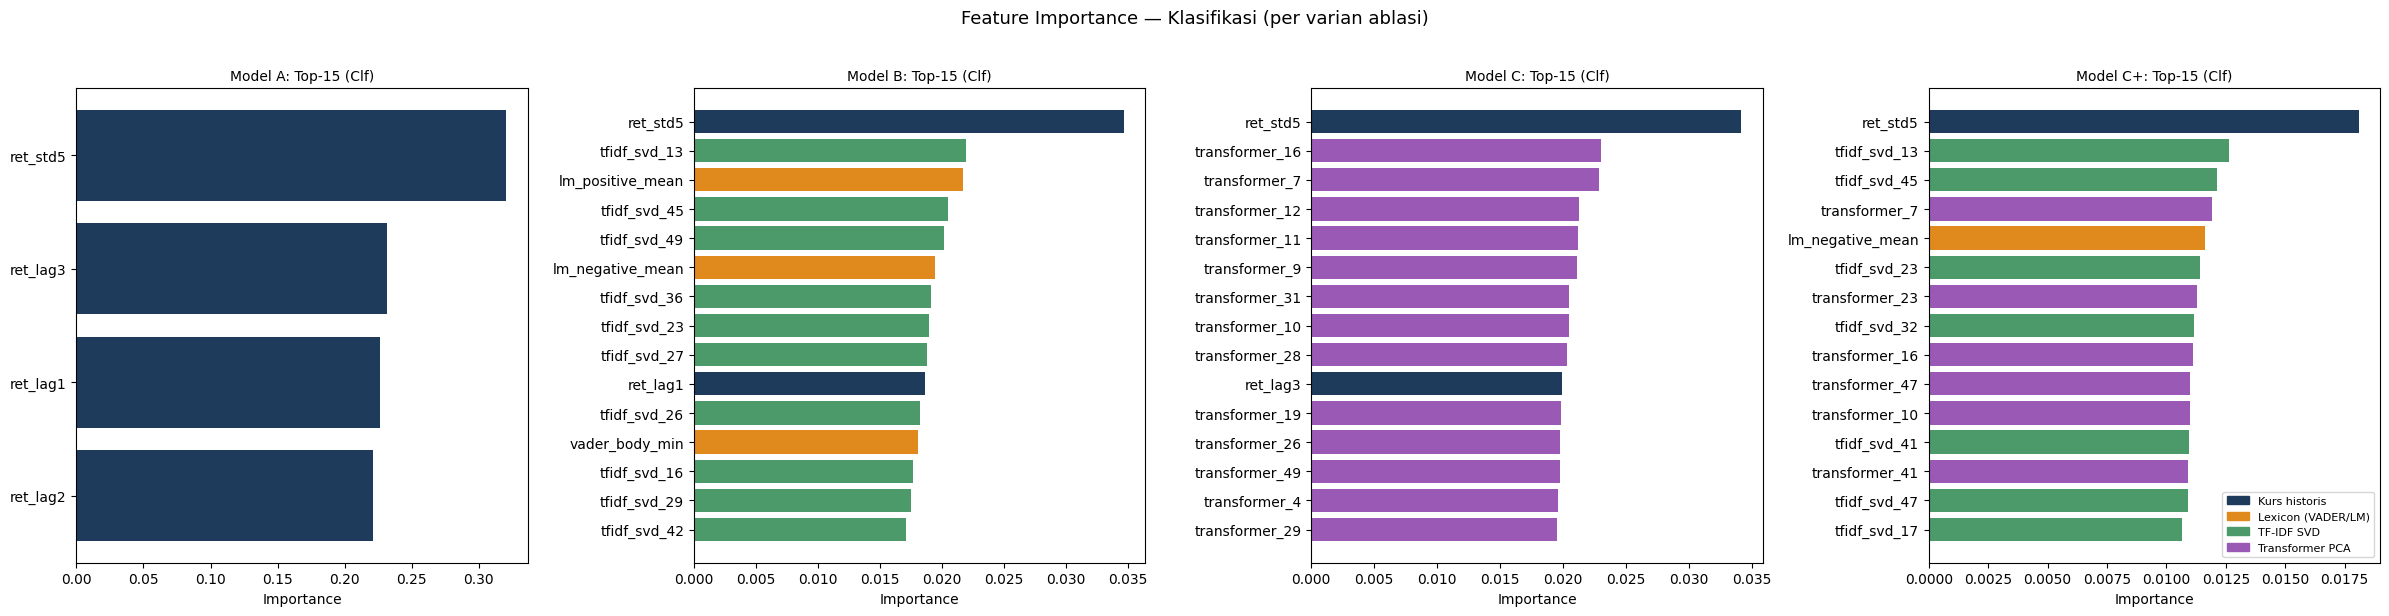

In [12]:
def group_of(f):
    if f in FEAT_TS: return "Kurs historis"
    if f.startswith("tfidf_svd_"): return "TF-IDF SVD"
    if f.startswith("transformer_"): return "Transformer PCA"
    return "Lexicon (VADER/LM)"

colors = {
    "Kurs historis": "#1f3b5c",
    "Lexicon (VADER/LM)": "#e08a1e",
    "TF-IDF SVD": "#4c9a6a",
    "Transformer PCA": "#9b59b6",
}

# Porsi importance per kelompok fitur (klasifikasi)
print("Porsi Feature Importance per kelompok — Klasifikasi (Test):\n")
share_data = {}
for vname, clf in clf_models.items():
    feat_cols = MODEL_VARIANTS[vname]
    imp = pd.Series(clf.feature_importances_, index=feat_cols)
    groups = imp.groupby(group_of).sum()
    share_data[vname.split(":")[0]] = groups

share_df = pd.DataFrame(share_data).fillna(0).round(4)
display(share_df)

# Top-15 feature importance per varian (klasifikasi)
fig, axes = plt.subplots(1, n_variants, figsize=(6 * n_variants, 6))
if n_variants == 1:
    axes = [axes]

for ax, vname in zip(axes, variant_names):
    feat_cols = MODEL_VARIANTS[vname]
    imp = pd.Series(clf_models[vname].feature_importances_, index=feat_cols)
    top = imp.sort_values(ascending=False).head(15).sort_values()
    ax.barh(top.index, top.values, color=[colors[group_of(f)] for f in top.index])
    short = vname.split(":")[0]
    ax.set_title(f"{short}: Top-15 (Clf)", fontsize=10)
    ax.set_xlabel("Importance")

# Legend
handles = [plt.Rectangle((0, 0), 1, 1, color=c) for c in colors.values()]
axes[-1].legend(handles, colors.keys(), loc="lower right", fontsize=8)

plt.suptitle("Feature Importance — Klasifikasi (per varian ablasi)", fontsize=13, y=1.02)
plt.tight_layout()
plt.savefig(RESULTS_DIR / "04b_ablasi_feature_importance.png", dpi=150, bbox_inches="tight")
plt.show()

## 13. Visualisasi regresi: prediksi vs aktual (test set)

Overlay time-series prediksi dari semua varian terhadap kurs aktual.

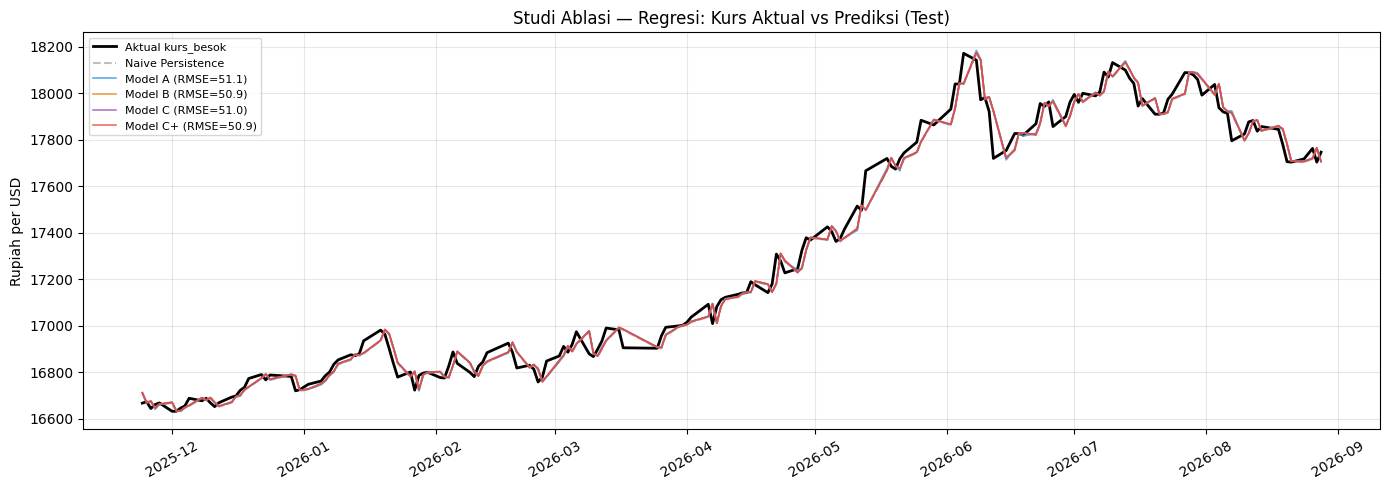

In [13]:
d_te = splits["test"]

fig, ax = plt.subplots(figsize=(14, 5))
ax.plot(d_te["date"], y_reg["test"], label="Aktual kurs_besok", lw=2, color="black")
ax.plot(d_te["date"], kurs_today["test"], label="Naive Persistence", ls="--", alpha=0.5, color="grey")

variant_colors = ["#3498db", "#e08a1e", "#9b59b6", "#e74c3c"]
for (vname, pred), color in zip(reg_preds.items(), variant_colors):
    short = vname.split(":")[0]
    rmse = reg_metrics_all[(vname, "test")]["rmse"]
    ax.plot(d_te["date"], pred["test"], label=f"{short} (RMSE={rmse:.1f})",
            lw=1.2, alpha=0.8, color=color)

ax.set_title("Studi Ablasi — Regresi: Kurs Aktual vs Prediksi (Test)")
ax.set_ylabel("Rupiah per USD")
ax.legend(fontsize=8, loc="upper left")
ax.tick_params(axis="x", rotation=30)
ax.grid(alpha=0.3)
plt.tight_layout()
plt.savefig(RESULTS_DIR / "04b_ablasi_trajectory.png", dpi=150)
plt.show()

## 14. Scatter plot: delta prediksi vs aktual (test set)

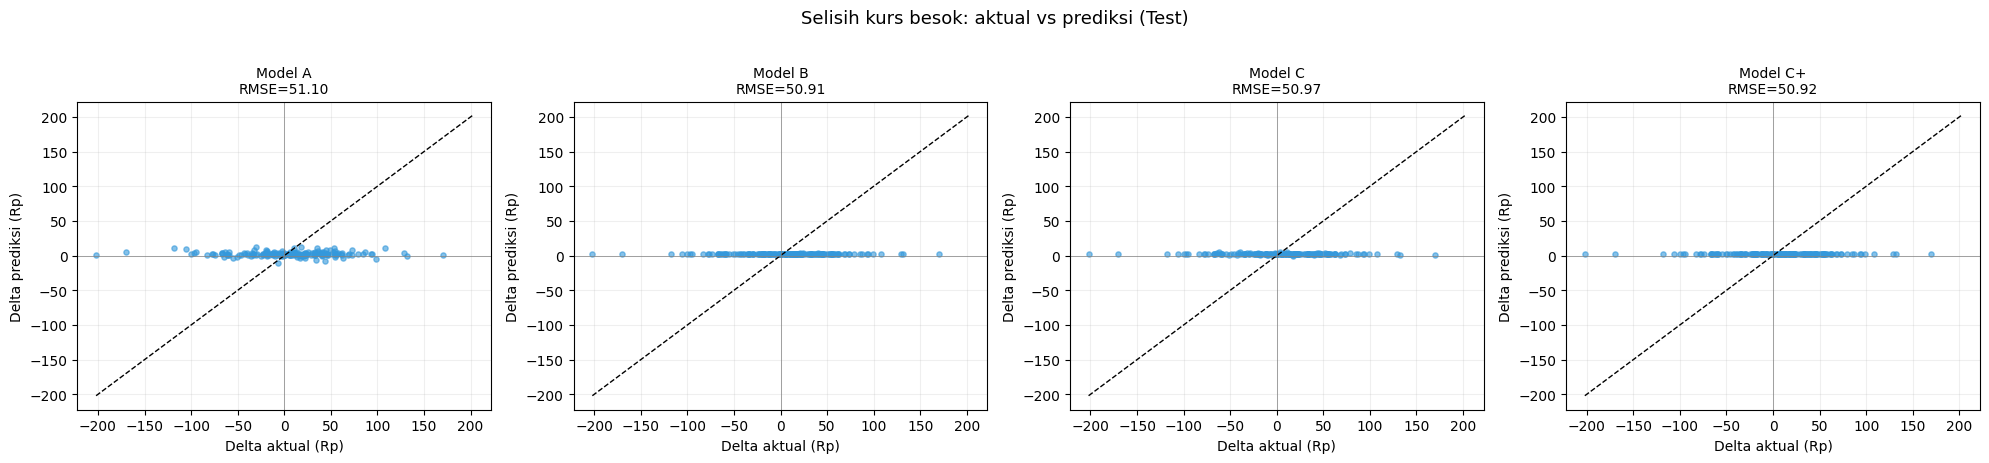

In [14]:
actual_delta = y_delta["test"].to_numpy()

fig, axes = plt.subplots(1, n_variants, figsize=(5 * n_variants, 4.5))
if n_variants == 1:
    axes = [axes]

for ax, (vname, pred) in zip(axes, reg_preds.items()):
    pred_delta = pred["test"] - kurs_today["test"]
    lim = float(max(np.abs(actual_delta).max(), np.abs(pred_delta).max()))
    
    ax.scatter(actual_delta, pred_delta, s=14, alpha=0.6, color="#3498db")
    ax.plot([-lim, lim], [-lim, lim], "k--", lw=1)
    ax.axhline(0, color="grey", lw=0.5); ax.axvline(0, color="grey", lw=0.5)
    ax.set_xlabel("Delta aktual (Rp)")
    ax.set_ylabel("Delta prediksi (Rp)")
    short = vname.split(":")[0]
    rmse = reg_metrics_all[(vname, "test")]["rmse"]
    ax.set_title(f"{short}\nRMSE={rmse:.2f}", fontsize=10)
    ax.grid(alpha=0.2)

plt.suptitle("Selisih kurs besok: aktual vs prediksi (Test)", fontsize=13, y=1.02)
plt.tight_layout()
plt.savefig(RESULTS_DIR / "04b_ablasi_scatter_delta.png", dpi=150, bbox_inches="tight")
plt.show()

## 15. Simpan hasil

In [15]:
# CSV tabel perbandingan
res.round(6).to_csv(RESULTS_DIR / "04b_ablasi_comparison.csv", index=False)

# JSON detail
out = {
    "experiment": "Studi Ablasi Tugas 3",
    "variants": {},
    "rmse_naive_same_rows": rmse_naive,
}

for vname in MODEL_VARIANTS:
    out["variants"][vname] = {
        "n_features": len(MODEL_VARIANTS[vname]),
        "feature_groups": {
            g: sum(1 for f in MODEL_VARIANTS[vname] if group_of(f) == g)
            for g in set(group_of(f) for f in MODEL_VARIANTS[vname])
        },
        "classification": {
            s: {k: v for k, v in clf_metrics_all[(vname, s)].items()}
            for s in ["val", "test"]
        },
        "regression": {
            s: reg_metrics_all[(vname, s)]
            for s in ["val", "test"]
        },
    }

with open(RESULTS_DIR / "04b_ablasi_results.json", "w", encoding="utf-8") as f:
    json.dump(out, f, ensure_ascii=False, indent=2)

print("Tersimpan di:", RESULTS_DIR)
for n in ["04b_ablasi_comparison.csv", "04b_ablasi_results.json",
          "04b_ablasi_classification.png", "04b_ablasi_regression.png",
          "04b_ablasi_confusion_matrices.png", "04b_ablasi_feature_importance.png",
          "04b_ablasi_trajectory.png", "04b_ablasi_scatter_delta.png"]:
    print(" -", n)

Tersimpan di: C:\kuliahlocal\smt 5\NLP\nlp-trio-bertiga\results
 - 04b_ablasi_comparison.csv
 - 04b_ablasi_results.json
 - 04b_ablasi_classification.png
 - 04b_ablasi_regression.png
 - 04b_ablasi_confusion_matrices.png
 - 04b_ablasi_feature_importance.png
 - 04b_ablasi_trajectory.png
 - 04b_ablasi_scatter_delta.png
